# Substructure Analysis — KMeans + Elbow Test

Same three datasets as the DBSCAN notebook, but clustered with **KMeans**.

**Pipeline per group:**
1. ECFP4 Morgan fingerprints (radius=2, 2048 bits)
2. UMAP projection (Jaccard metric)
3. Elbow test: plot inertia and silhouette score over k=2..15 → select optimal k
4. KMeans(k) on UMAP embedding
5. MCS core per cluster; 3–5 most central representatives


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from rdkit import Chem, DataStructs
from rdkit.Chem import Draw, rdFingerprintGenerator, rdFMCS
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import umap
import warnings
warnings.filterwarnings('ignore')

BASE = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/'
gen  = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def to_fp_matrix(mols):
    fps = [gen.GetFingerprint(m) for m in mols]
    return fps, np.array([list(fp.ToBitString()) for fp in fps], dtype=np.float32)

def plot_umap(fp_matrix, labels, title='UMAP', color_map=None, annotate=None):
    n = len(fp_matrix)
    reducer = umap.UMAP(n_neighbors=min(15, n - 1),
                        min_dist=0.3, metric='jaccard', random_state=42)
    emb = reducer.fit_transform(fp_matrix)
    unique = list(dict.fromkeys(labels))
    if color_map is None:
        color_map = {l: plt.cm.tab10(i % 10) for i, l in enumerate(unique)}
    fig, ax = plt.subplots(figsize=(8, 6))
    for lbl in unique:
        mask = np.array([l == lbl for l in labels])
        ax.scatter(emb[mask, 0], emb[mask, 1], c=[color_map[lbl]],
                   label=lbl, s=80, edgecolors='black', linewidths=0.5, alpha=0.85)
    if annotate is not None:
        for i, txt in enumerate(annotate):
            ax.annotate(str(txt), (emb[i, 0], emb[i, 1]),
                        textcoords='offset points', xytext=(4, 3), fontsize=6.5, color='#444')
    ax.legend(loc='upper left', fontsize=8.5, framealpha=0.9)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
    plt.tight_layout(); plt.show()
    return emb

def get_mcs_core(mols):
    if len(mols) < 2:
        return None
    mcs = rdFMCS.FindMCS(mols, ringMatchesRingOnly=True,
                         completeRingsOnly=True, timeout=10)
    if mcs and mcs.numAtoms > 0:
        return Chem.MolFromSmarts(mcs.smartsString)
    return None

def draw_cluster_reps(dataset, name_map, title, mols_per_row=5, img_size=(280, 230)):
    """Draw one representative + MCS core per cluster."""
    from IPython.display import display
    import pubchempy as pcp

    reps, legs, highlights = [], [], []
    cl_name_map = {}
    print(f'Fetching PubChem names for {title}...')

    for cl in sorted(dataset['cluster'].unique()):
        sub  = dataset[dataset['cluster'] == cl].reset_index(drop=True)
        fps  = sub['fp'].tolist()
        avg  = [sum(DataStructs.BulkTanimotoSimilarity(fp, fps)) for fp in fps]
        rep  = sub.loc[int(np.argmax(avg))]
        cid  = int(rep['PUBCHEM_CID'])
        try:
            c_   = pcp.Compound.from_cid(cid)
            syns = c_.synonyms or []
            short = [s for s in syns if len(s) <= 30 and s[0].isalpha()]
            name  = short[0] if short else (syns[0][:28] if syns else str(cid))
        except Exception:
            name = str(cid)
        cl_name_map[cl] = name

        core = get_mcs_core(sub['mol'].tolist())
        if core is not None:
            reps.append(core)
            legs.append(f'C{cl} (n={len(sub)}) ★ Core ★')
            highlights.append([])

        reps.append(rep['mol'])
        legs.append(f'C{cl} (n={len(sub)})\n{name} [CID {cid}]')
        match = rep['mol'].GetSubstructMatch(core) if core is not None else []
        highlights.append(list(match))
        print(f'  Cluster {cl:2d} (n={len(sub):3d})  {name}  [CID {cid}]')

    img = Draw.MolsToGridImage(reps, molsPerRow=mols_per_row, subImgSize=img_size,
                               legends=legs, highlightAtomLists=highlights,
                               returnPNG=False)
    display(img)
    return cl_name_map

def umap_by_cluster(dataset, cl_name_map, title):
    fig, ax = plt.subplots(figsize=(9, 7))
    cmap = plt.cm.tab10
    for cl in sorted(dataset['cluster'].unique()):
        sub  = dataset[dataset['cluster'] == cl]
        name = cl_name_map.get(cl, f'Cluster {cl}')
        ax.scatter(sub['umap_x'], sub['umap_y'], c=[cmap(cl % 10)],
                   s=70, edgecolors='black', linewidths=0.5, alpha=0.85,
                   label=f'C{cl}: {name} (n={len(sub)})')
    for _, row in dataset.iterrows():
        ax.annotate(str(int(row['PUBCHEM_CID'])), (row['umap_x'], row['umap_y']),
                    textcoords='offset points', xytext=(4, 3), fontsize=6, color='#444')
    ax.legend(loc='upper left', fontsize=7.5, framealpha=0.95, ncol=2)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
    plt.tight_layout(); plt.show()

def elbow_test(emb, k_min=2, k_max=15, title=''):
    """
    Plot inertia (elbow) and silhouette score over k=k_min..k_max.
    Inertia:    sum of squared distances from each point to its cluster centre.
                Lower is better; the 'elbow' is where improvement slows down.
    Silhouette: how well each point fits its own cluster vs the next closest.
                Range -1 to 1; higher is better; peak = best k.
    Returns the k with highest silhouette score.
    """
    ks         = range(k_min, k_max + 1)
    inertias   = []
    silhouettes = []

    for k in ks:
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = km.fit_predict(emb)
        inertias.append(km.inertia_)
        silhouettes.append(silhouette_score(emb, labels))

    best_k = k_min + int(np.argmax(silhouettes))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    # Elbow plot
    ax1.plot(list(ks), inertias, 'bo-', linewidth=1.5, markersize=5)
    ax1.set_xlabel('Number of clusters k')
    ax1.set_ylabel('Inertia (within-cluster sum of squares)')
    ax1.set_title(f'{title}\nElbow plot — look for the bend')
    ax1.grid(True, alpha=0.3)

    # Silhouette plot
    ax2.plot(list(ks), silhouettes, 'rs-', linewidth=1.5, markersize=5)
    ax2.axvline(best_k, color='red', linestyle='--', linewidth=1.2,
                label=f'best k = {best_k} (silhouette={max(silhouettes):.3f})')
    ax2.set_xlabel('Number of clusters k')
    ax2.set_ylabel('Silhouette score (higher = better)')
    ax2.set_title(f'{title}\nSilhouette score — peak = best k')
    ax2.legend(fontsize=9)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout(); plt.show()

    print(f'Best k by silhouette: {best_k}  (score={max(silhouettes):.4f})')
    for k, ine, sil in zip(ks, inertias, silhouettes):
        marker = ' <-- best' if k == best_k else ''
        print(f'  k={k:2d}  inertia={ine:8.2f}  silhouette={sil:.4f}{marker}')

    return best_k

def pick_central(sub, n_min=3, n_max=5):
    """Return n_min-n_max rows closest to cluster centroid in UMAP space."""
    coords   = sub[['umap_x', 'umap_y']].values
    centroid = coords.mean(axis=0)
    dists    = np.linalg.norm(coords - centroid, axis=1)
    n_pick   = max(n_min, min(n_max, len(sub)))
    return sub.iloc[np.argsort(dists)[:n_pick]].reset_index(drop=True)

print('Setup complete.')

Setup complete.


---
## Load Data

In [2]:
df = pd.read_csv(BASE + 'results/all_cell_line_comparisions/consistent_compounds_caspase_all.csv')
ASSAY_COLS = [c for c in df.columns if c not in ('PUBCHEM_CID', 'pattern', 'behavior')]

smi_dfs = []
for fname in os.listdir(BASE + 'cleaned_datasets'):
    if not fname.endswith('.csv'):
        continue
    try:
        tmp = pd.read_csv(BASE + 'cleaned_datasets/' + fname,
                          usecols=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'],
                          low_memory=False)
        smi_dfs.append(tmp)
    except Exception:
        pass

smiles_df = (pd.concat(smi_dfs)
               .dropna(subset=['PUBCHEM_EXT_DATASOURCE_SMILES'])
               .drop_duplicates('PUBCHEM_CID')
               .reset_index(drop=True))
print(f'SMILES lookup: {len(smiles_df)} unique compounds')

fully_tested = df[df[ASSAY_COLS].notna().all(axis=1)].copy()
fully_tested['n_active'] = (fully_tested[ASSAY_COLS] == 'Active').sum(axis=1)
cids_104 = fully_tested[fully_tested['n_active'] >= 1]['PUBCHEM_CID'].tolist()
print(f'Group 104: {len(cids_104)} compounds')

cids_66 = df[df['behavior'] == 'Active']['PUBCHEM_CID'].tolist()
print(f'Group 66:  {len(cids_66)} compounds')
print(f'Overlap:   {len(set(cids_104) & set(cids_66))} (should be 0)')

SMILES lookup: 8777 unique compounds
Group 104: 104 compounds
Group 66:  66 compounds
Overlap:   0 (should be 0)


---
## Section 1 — 104 Compounds: Fully-Tested, Active in ≥1 Cell Line

In [3]:
g104 = (pd.DataFrame({'PUBCHEM_CID': cids_104})
          .merge(smiles_df, on='PUBCHEM_CID', how='left'))
g104 = g104.merge(fully_tested[['PUBCHEM_CID', 'n_active']], on='PUBCHEM_CID', how='left')
g104['mol'] = g104['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(
    lambda s: Chem.MolFromSmiles(s) if pd.notna(s) else None)
g104 = g104[g104['mol'].notna()].reset_index(drop=True)

def activity_bin(n):
    if n == 1:  return '1 cell line'
    if n <= 3:  return '2-3 cell lines'
    if n <= 7:  return '4-7 cell lines'
    return '8+ cell lines (pan-toxic)'

g104['activity_bin'] = g104['n_active'].apply(activity_bin)
g104['fp'], fp_matrix_104 = to_fp_matrix(g104['mol'].tolist())
print(g104['activity_bin'].value_counts())
print(f'\n{len(g104)} compounds with valid SMILES')

activity_bin
1 cell line                  62
2-3 cell lines               25
4-7 cell lines               13
8+ cell lines (pan-toxic)     4
Name: count, dtype: int64

104 compounds with valid SMILES


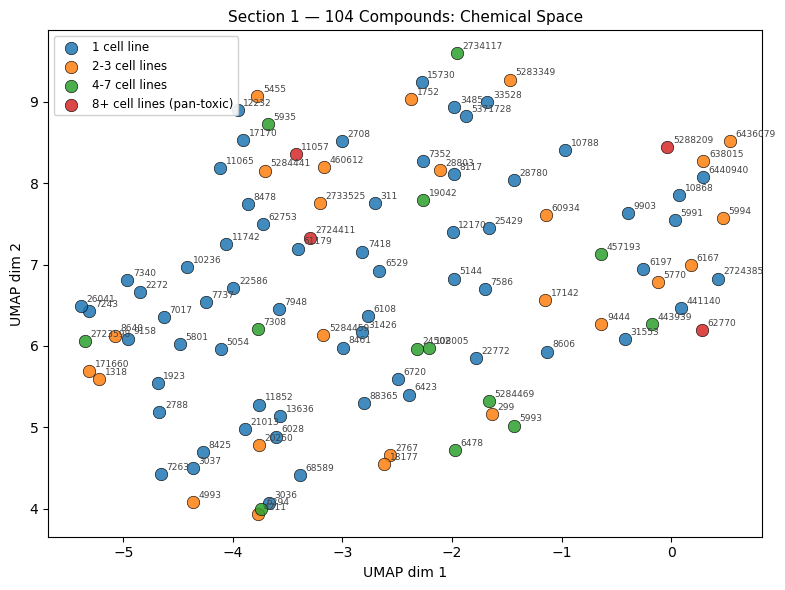

In [4]:
color_map_104 = {
    '1 cell line':               '#1f77b4',
    '2-3 cell lines':            '#ff7f0e',
    '4-7 cell lines':            '#2ca02c',
    '8+ cell lines (pan-toxic)': '#d62728',
}
emb_104 = plot_umap(
    fp_matrix_104,
    labels    = g104['activity_bin'].tolist(),
    title     = 'Section 1 — 104 Compounds: Chemical Space',
    color_map = color_map_104,
    annotate  = g104['PUBCHEM_CID'].astype(int),
)
g104['umap_x'], g104['umap_y'] = emb_104[:, 0], emb_104[:, 1]

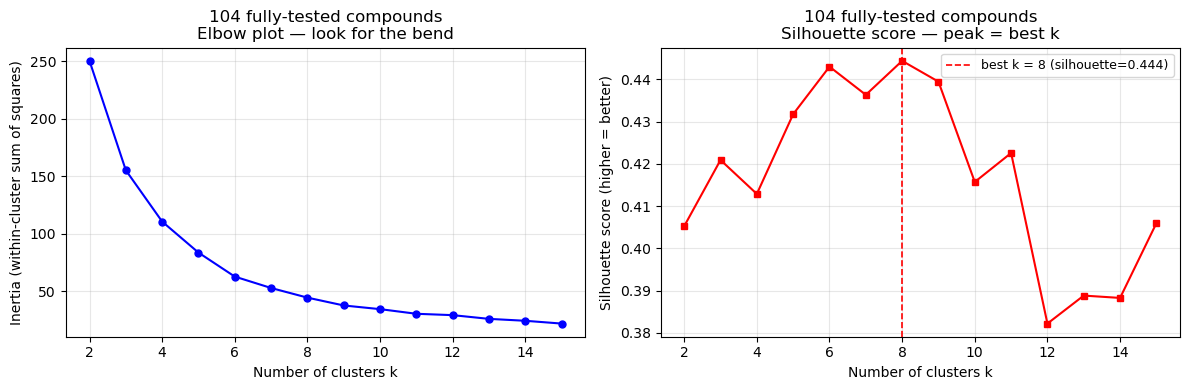

Best k by silhouette: 8  (score=0.4444)
  k= 2  inertia=  250.16  silhouette=0.4053
  k= 3  inertia=  155.13  silhouette=0.4209
  k= 4  inertia=  110.56  silhouette=0.4129
  k= 5  inertia=   83.62  silhouette=0.4318
  k= 6  inertia=   62.77  silhouette=0.4430
  k= 7  inertia=   52.87  silhouette=0.4364
  k= 8  inertia=   44.50  silhouette=0.4444 <-- best
  k= 9  inertia=   37.69  silhouette=0.4395
  k=10  inertia=   34.51  silhouette=0.4157
  k=11  inertia=   30.47  silhouette=0.4226
  k=12  inertia=   29.29  silhouette=0.3822
  k=13  inertia=   26.06  silhouette=0.3888
  k=14  inertia=   24.39  silhouette=0.3883
  k=15  inertia=   21.96  silhouette=0.4060


In [5]:
# Elbow test: try k=2..15, plot inertia and silhouette, return best k
K_104 = elbow_test(emb_104, k_min=2, k_max=15,
                   title='104 fully-tested compounds')

In [6]:
# Override K_104 here if you prefer the visual elbow over the silhouette peak
# K_104 = 8

km_104 = KMeans(n_clusters=K_104, random_state=42, n_init=10)
g104['cluster'] = km_104.fit_predict(emb_104)
print(f'KMeans (104): {K_104} clusters')
print(pd.Series(g104['cluster']).value_counts().sort_index())

KMeans (104): 8 clusters
cluster
0    16
1     9
2    15
3    18
4    13
5    14
6    12
7     7
Name: count, dtype: int64


Fetching PubChem names for 104 fully-tested active compounds...
  Cluster  0 (n= 16)  EINECS 243-511-6  [CID 88365]
  Cluster  1 (n=  9)  all-trans-Retinal  [CID 638015]
  Cluster  2 (n= 15)  Malachite Green Oxalate  [CID 2724411]
  Cluster  3 (n= 18)  O-AMINOPHENOL  [CID 5801]
  Cluster  4 (n= 13)  Furfuryl acetate  [CID 12170]
  Cluster  5 (n= 14)  Dichlorophen  [CID 3037]
  Cluster  6 (n= 12)  Doxorubicin Hydrochloride  [CID 443939]
  Cluster  7 (n=  7)  15730  [CID 15730]


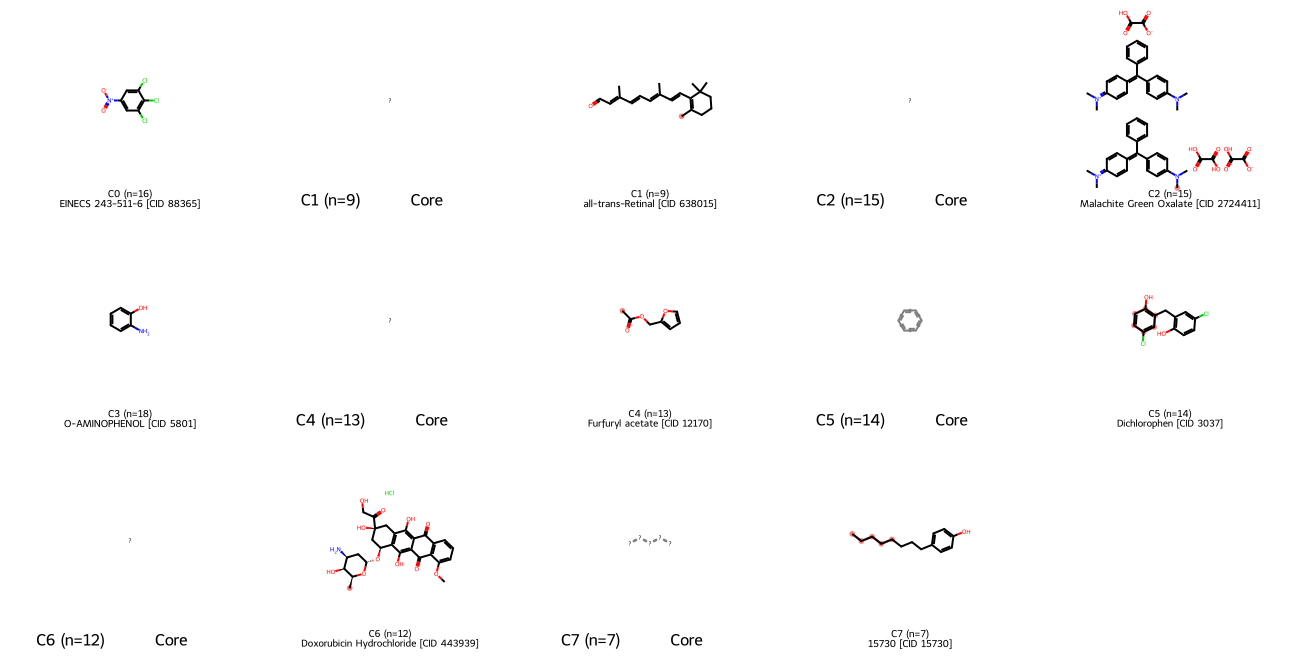

In [7]:
cl_name_104 = draw_cluster_reps(
    g104, {}, title='104 fully-tested active compounds',
    mols_per_row=5, img_size=(260, 220))

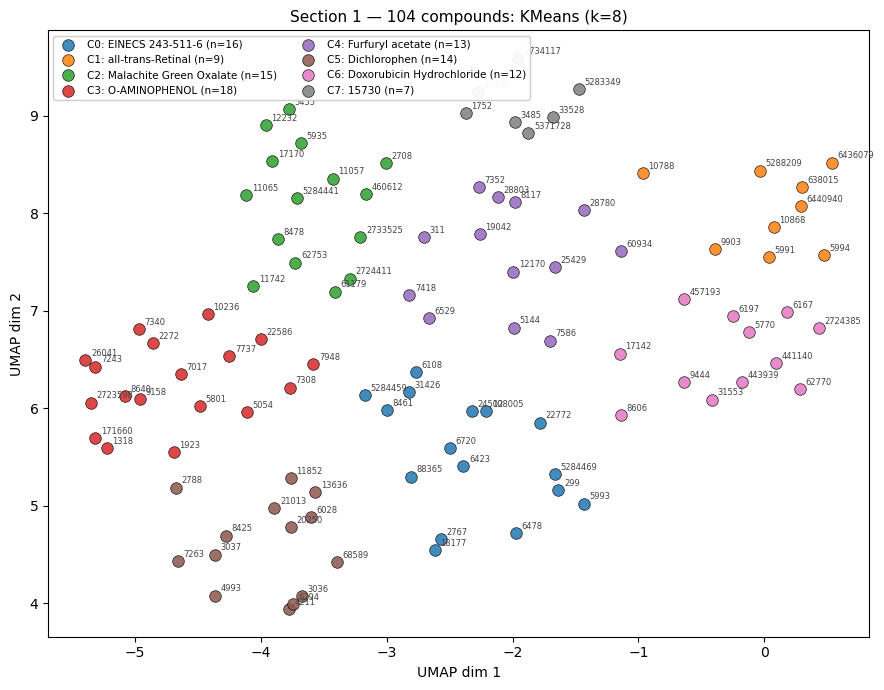

In [8]:
umap_by_cluster(
    g104, cl_name_104,
    title=f'Section 1 — 104 compounds: KMeans (k={K_104})')

### Section 1 — MCS Core Detail per Cluster (3–5 most central representatives)

Drawing 48 panels across 8 cluster(s)


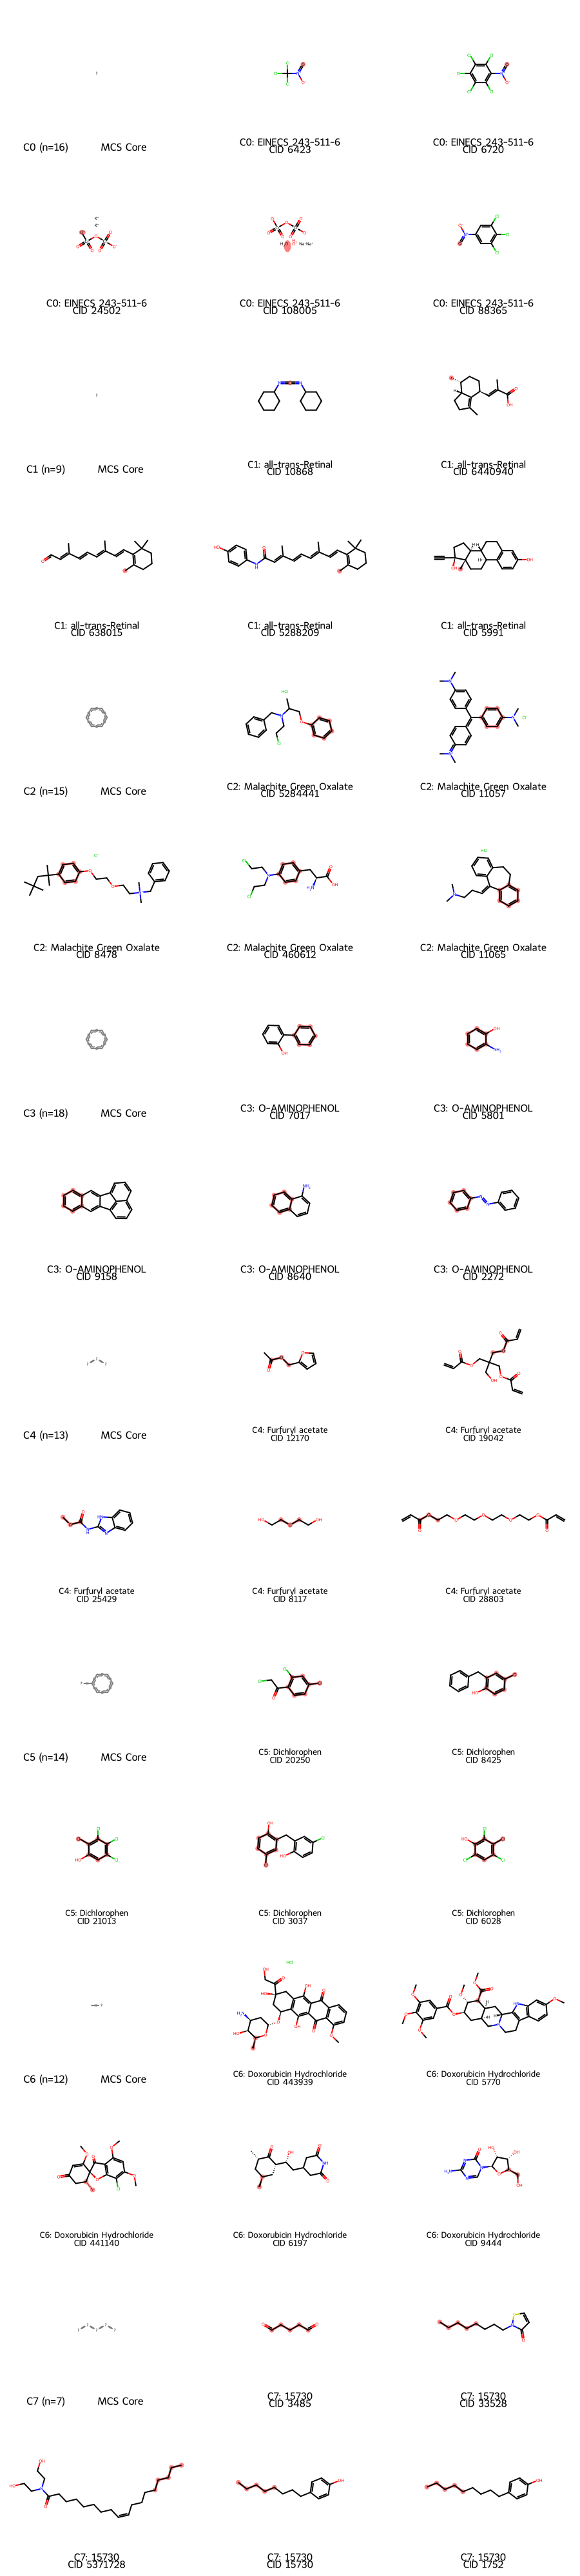

In [9]:
from IPython.display import display

CLUSTERS     = None
MOLS_PER_ROW = 3

cluster_ids = sorted(g104['cluster'].unique())
if CLUSTERS is not None:
    cluster_ids = [c for c in cluster_ids if c in CLUSTERS]

mols, legends, highlights = [], [], []

for cl in cluster_ids:
    sub   = g104[g104['cluster'] == cl].reset_index(drop=True)
    shown = pick_central(sub)
    core  = get_mcs_core(shown['mol'].tolist())
    name  = cl_name_104.get(cl, f'Cluster {cl}')

    if core is not None:
        mols.append(core)
        legends.append(f'C{cl} (n={len(sub)}) ★ MCS Core ★')
        highlights.append([])

    for _, row in shown.iterrows():
        mol = row['mol']
        mols.append(mol)
        legends.append(f'C{cl}: {name}\nCID {int(row["PUBCHEM_CID"])}')
        match = mol.GetSubstructMatch(core) if core is not None else []
        highlights.append(list(match))

print(f'Drawing {len(mols)} panels across {len(cluster_ids)} cluster(s)')
if mols:
    img = Draw.MolsToGridImage(mols, molsPerRow=MOLS_PER_ROW, subImgSize=(300, 250),
                               legends=legends, highlightAtomLists=highlights,
                               returnPNG=False)
    display(img)

---
## Section 2 — 66 Compounds: CHO-K1 + HepG2 Active

In [10]:
g66 = (pd.DataFrame({'PUBCHEM_CID': cids_66})
         .merge(smiles_df, on='PUBCHEM_CID', how='left'))
g66['mol'] = g66['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(
    lambda s: Chem.MolFromSmiles(s) if pd.notna(s) else None)
g66 = g66[g66['mol'].notna()].reset_index(drop=True)
g66['fp'], fp_matrix_66 = to_fp_matrix(g66['mol'].tolist())
print(f'{len(g66)} compounds with valid SMILES')

66 compounds with valid SMILES


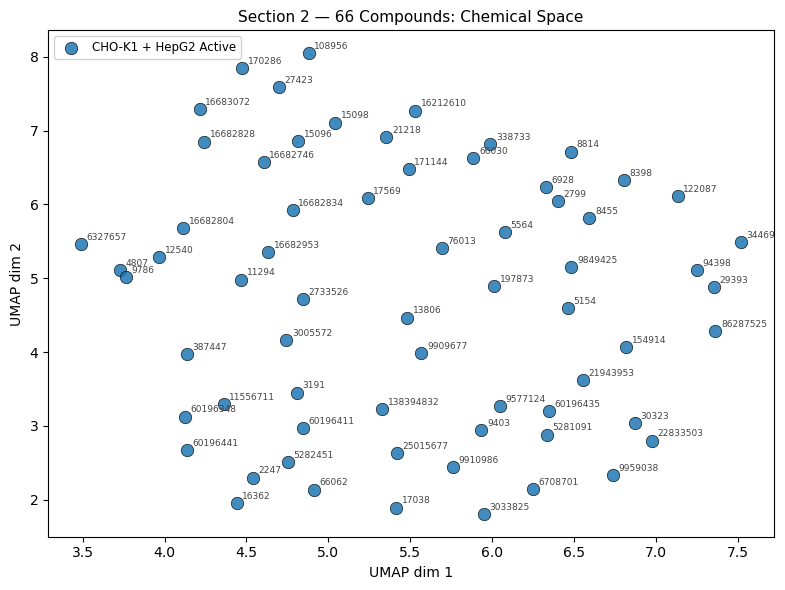

In [11]:
emb_66 = plot_umap(
    fp_matrix_66,
    labels   = ['CHO-K1 + HepG2 Active'] * len(g66),
    title    = 'Section 2 — 66 Compounds: Chemical Space',
    annotate = g66['PUBCHEM_CID'].astype(int),
)
g66['umap_x'], g66['umap_y'] = emb_66[:, 0], emb_66[:, 1]

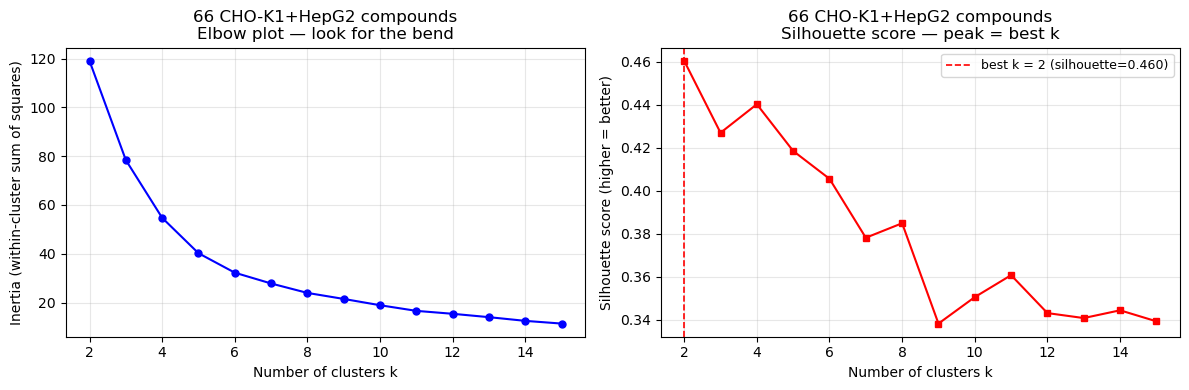

Best k by silhouette: 2  (score=0.4603)
  k= 2  inertia=  119.04  silhouette=0.4603 <-- best
  k= 3  inertia=   78.40  silhouette=0.4269
  k= 4  inertia=   54.74  silhouette=0.4401
  k= 5  inertia=   40.24  silhouette=0.4185
  k= 6  inertia=   32.27  silhouette=0.4055
  k= 7  inertia=   27.84  silhouette=0.3781
  k= 8  inertia=   23.97  silhouette=0.3849
  k= 9  inertia=   21.51  silhouette=0.3383
  k=10  inertia=   18.93  silhouette=0.3506
  k=11  inertia=   16.62  silhouette=0.3608
  k=12  inertia=   15.42  silhouette=0.3432
  k=13  inertia=   14.04  silhouette=0.3408
  k=14  inertia=   12.52  silhouette=0.3444
  k=15  inertia=   11.41  silhouette=0.3393


In [12]:
K_66 = elbow_test(emb_66, k_min=2, k_max=15,
                  title='66 CHO-K1+HepG2 compounds')

In [13]:
# Override K_66 here if you prefer the visual elbow
# K_66 = 5

km_66 = KMeans(n_clusters=K_66, random_state=42, n_init=10)
g66['cluster'] = km_66.fit_predict(emb_66)
print(f'KMeans (66): {K_66} clusters')
print(pd.Series(g66['cluster']).value_counts().sort_index())

KMeans (66): 2 clusters
cluster
0    36
1    30
Name: count, dtype: int64


Fetching PubChem names for 66 CHO-K1+HepG2 active compounds...
  Cluster  0 (n= 36)  TRIBUTYLTIN BENZOATE  [CID 16682834]
  Cluster  1 (n= 30)  ebastine  [CID 3191]


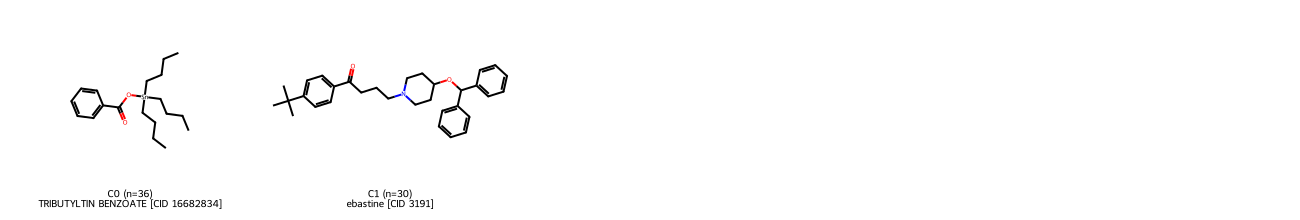

In [14]:
cl_name_66 = draw_cluster_reps(
    g66, {}, title='66 CHO-K1+HepG2 active compounds',
    mols_per_row=5, img_size=(260, 220))

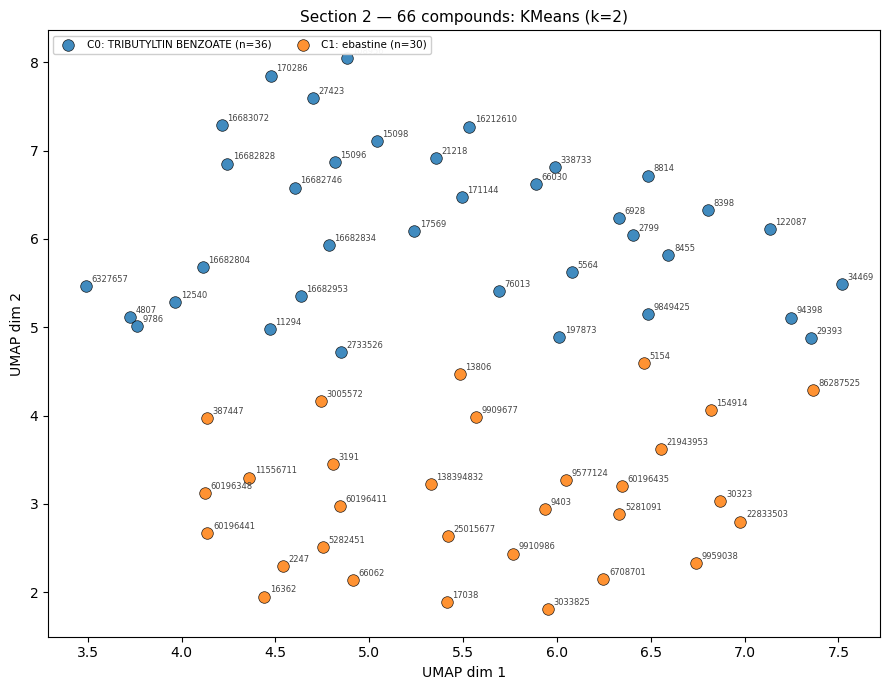

In [15]:
umap_by_cluster(
    g66, cl_name_66,
    title=f'Section 2 — 66 compounds: KMeans (k={K_66})')

### Section 2 — MCS Core Detail per Cluster (3–5 most central representatives)

Drawing 12 panels across 2 cluster(s)


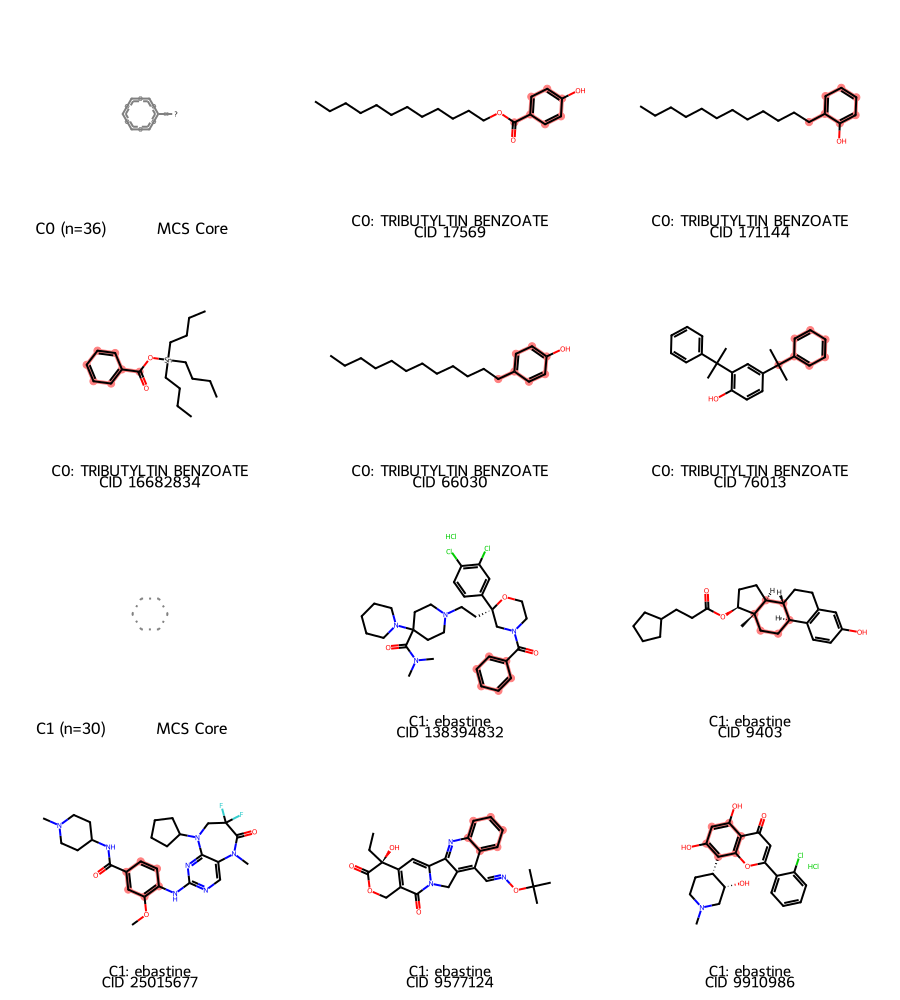

In [16]:
from IPython.display import display

CLUSTERS_66  = None
MOLS_PER_ROW = 3

cluster_ids_66 = sorted(g66['cluster'].unique())
if CLUSTERS_66 is not None:
    cluster_ids_66 = [c for c in cluster_ids_66 if c in CLUSTERS_66]

mols66, legs66, hi66 = [], [], []

for cl in cluster_ids_66:
    sub   = g66[g66['cluster'] == cl].reset_index(drop=True)
    shown = pick_central(sub)
    core  = get_mcs_core(shown['mol'].tolist())
    name  = cl_name_66.get(cl, f'Cluster {cl}')

    if core is not None:
        mols66.append(core)
        legs66.append(f'C{cl} (n={len(sub)}) ★ MCS Core ★')
        hi66.append([])

    for _, row in shown.iterrows():
        mol = row['mol']
        mols66.append(mol)
        legs66.append(f'C{cl}: {name}\nCID {int(row["PUBCHEM_CID"])}')
        match = mol.GetSubstructMatch(core) if core is not None else []
        hi66.append(list(match))

print(f'Drawing {len(mols66)} panels across {len(cluster_ids_66)} cluster(s)')
if mols66:
    img = Draw.MolsToGridImage(mols66, molsPerRow=MOLS_PER_ROW, subImgSize=(300, 250),
                               legends=legs66, highlightAtomLists=hi66, returnPNG=False)
    display(img)

---
## Section 3 — 170 Combined Compounds

In [17]:
g104_sub = g104[['PUBCHEM_CID', 'mol', 'fp', 'umap_x', 'umap_y']].copy()
g104_sub['group'] = '104 (fully tested)'

g66_sub = g66[['PUBCHEM_CID', 'mol', 'fp', 'umap_x', 'umap_y']].copy()
g66_sub['group'] = '66 (CHO-K1+HepG2)'

g170 = pd.concat([g104_sub, g66_sub], ignore_index=True)
_, fp_matrix_170 = to_fp_matrix(g170['mol'].tolist())
print(f'Combined: {len(g170)} compounds')

Combined: 170 compounds


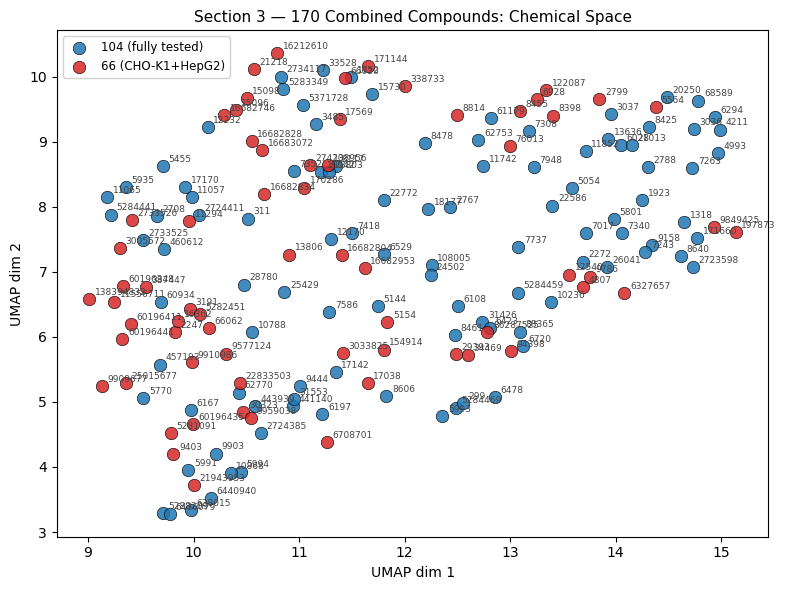

In [18]:
emb_170 = plot_umap(
    fp_matrix_170,
    labels    = g170['group'].tolist(),
    title     = 'Section 3 — 170 Combined Compounds: Chemical Space',
    color_map = {'104 (fully tested)': '#1f77b4', '66 (CHO-K1+HepG2)': '#d62728'},
    annotate  = g170['PUBCHEM_CID'].astype(int),
)
g170['umap_x'], g170['umap_y'] = emb_170[:, 0], emb_170[:, 1]

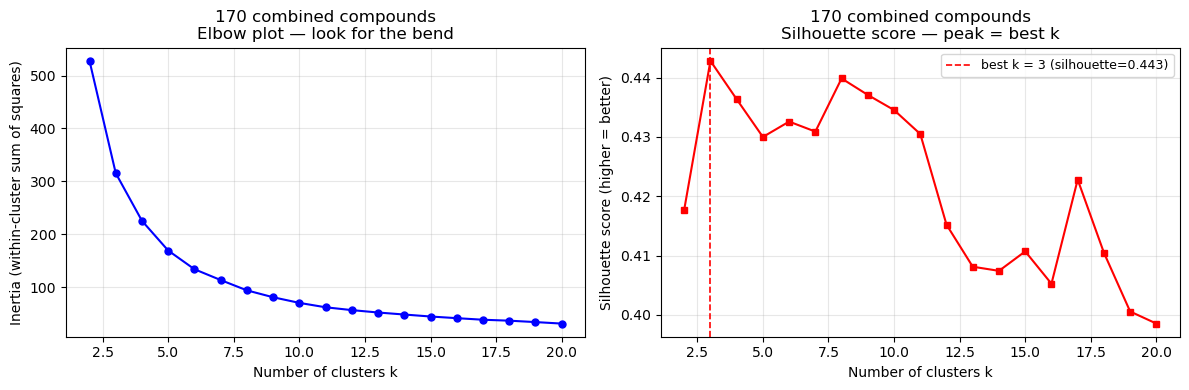

Best k by silhouette: 3  (score=0.4428)
  k= 2  inertia=  527.68  silhouette=0.4177
  k= 3  inertia=  315.59  silhouette=0.4428 <-- best
  k= 4  inertia=  225.60  silhouette=0.4364
  k= 5  inertia=  169.47  silhouette=0.4300
  k= 6  inertia=  134.23  silhouette=0.4326
  k= 7  inertia=  113.80  silhouette=0.4309
  k= 8  inertia=   94.32  silhouette=0.4399
  k= 9  inertia=   81.29  silhouette=0.4371
  k=10  inertia=   70.65  silhouette=0.4345
  k=11  inertia=   62.36  silhouette=0.4305
  k=12  inertia=   57.02  silhouette=0.4152
  k=13  inertia=   52.49  silhouette=0.4081
  k=14  inertia=   48.68  silhouette=0.4074
  k=15  inertia=   44.93  silhouette=0.4107
  k=16  inertia=   41.82  silhouette=0.4053
  k=17  inertia=   38.84  silhouette=0.4228
  k=18  inertia=   37.07  silhouette=0.4105
  k=19  inertia=   34.42  silhouette=0.4006
  k=20  inertia=   31.58  silhouette=0.3985


In [19]:
K_170 = elbow_test(emb_170, k_min=2, k_max=20,
                   title='170 combined compounds')

In [20]:
# Override K_170 here if you prefer the visual elbow
# K_170 = 10

km_170 = KMeans(n_clusters=K_170, random_state=42, n_init=10)
g170['cluster'] = km_170.fit_predict(emb_170)
print(f'KMeans (170): {K_170} clusters')
print(pd.Series(g170['cluster']).value_counts().sort_index())

print('\nCluster composition (both groups?):')
for cl in sorted(g170['cluster'].unique()):
    sub  = g170[g170['cluster'] == cl]
    n104 = (sub['group'] == '104 (fully tested)').sum()
    n66  = (sub['group'] == '66 (CHO-K1+HepG2)').sum()
    mixed = ' *** MIXED ***' if n104 > 0 and n66 > 0 else ''
    print(f'  C{cl}: n={len(sub)} | 104-group={n104} | 66-group={n66}{mixed}')

KMeans (170): 3 clusters
cluster
0    60
1    61
2    49
Name: count, dtype: int64

Cluster composition (both groups?):
  C0: n=60 | 104-group=31 | 66-group=29 *** MIXED ***
  C1: n=61 | 104-group=45 | 66-group=16 *** MIXED ***
  C2: n=49 | 104-group=28 | 66-group=21 *** MIXED ***


Fetching PubChem names for 170 combined active compounds...
  Cluster  0 (n= 60)  daunorubicin  [CID 30323]
  Cluster  1 (n= 61)  Clorophene  [CID 8425]
  Cluster  2 (n= 49)  Phenol, 4-octyl-  [CID 15730]


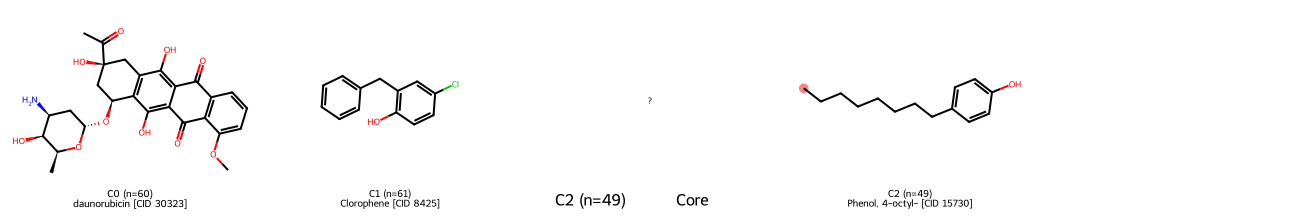

In [21]:
cl_name_170 = draw_cluster_reps(
    g170, {}, title='170 combined active compounds',
    mols_per_row=5, img_size=(260, 220))

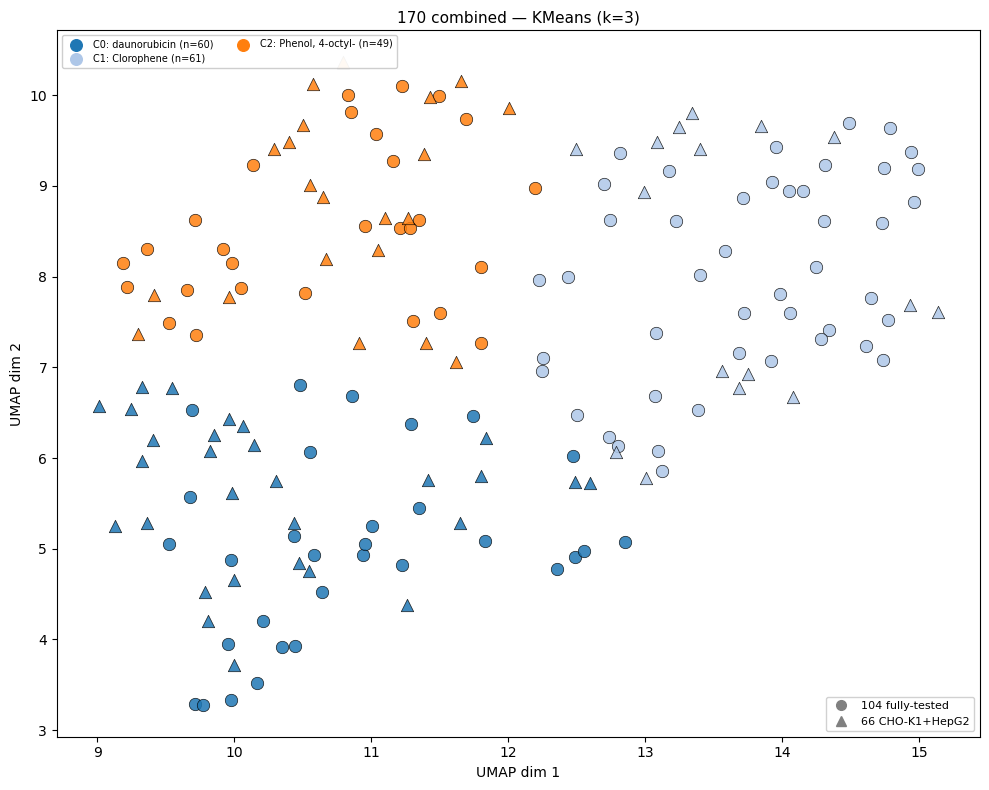

In [22]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(10, 8))
cmap = plt.cm.tab20
markers = {'104 (fully tested)': 'o', '66 (CHO-K1+HepG2)': '^'}

for cl in sorted(g170['cluster'].unique()):
    sub_cl = g170[g170['cluster'] == cl]
    name   = cl_name_170.get(cl, f'C{cl}')
    for grp, mkr in markers.items():
        sub = sub_cl[sub_cl['group'] == grp]
        if len(sub):
            ax.scatter(sub['umap_x'], sub['umap_y'], c=[cmap(cl % 20)],
                       marker=mkr, s=80, edgecolors='black', linewidths=0.5, alpha=0.85)
    ax.scatter([], [], c=[cmap(cl % 20)], s=70, label=f'C{cl}: {name} (n={len(sub_cl)})')

custom = [Line2D([0],[0], marker='o', color='grey', linestyle='None', markersize=7, label='104 fully-tested'),
          Line2D([0],[0], marker='^', color='grey', linestyle='None', markersize=7, label='66 CHO-K1+HepG2')]
leg1 = ax.legend(handles=custom, loc='lower right', fontsize=8, framealpha=0.9)
ax.add_artist(leg1)
ax.legend(loc='upper left', fontsize=7, framealpha=0.95, ncol=2)
ax.set_title(f'170 combined — KMeans (k={K_170})', fontsize=11)
ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
plt.tight_layout(); plt.show()

### Section 3 — MCS Core Detail per Cluster (3–5 most central representatives)

Drawing 18 panels across 3 cluster(s)


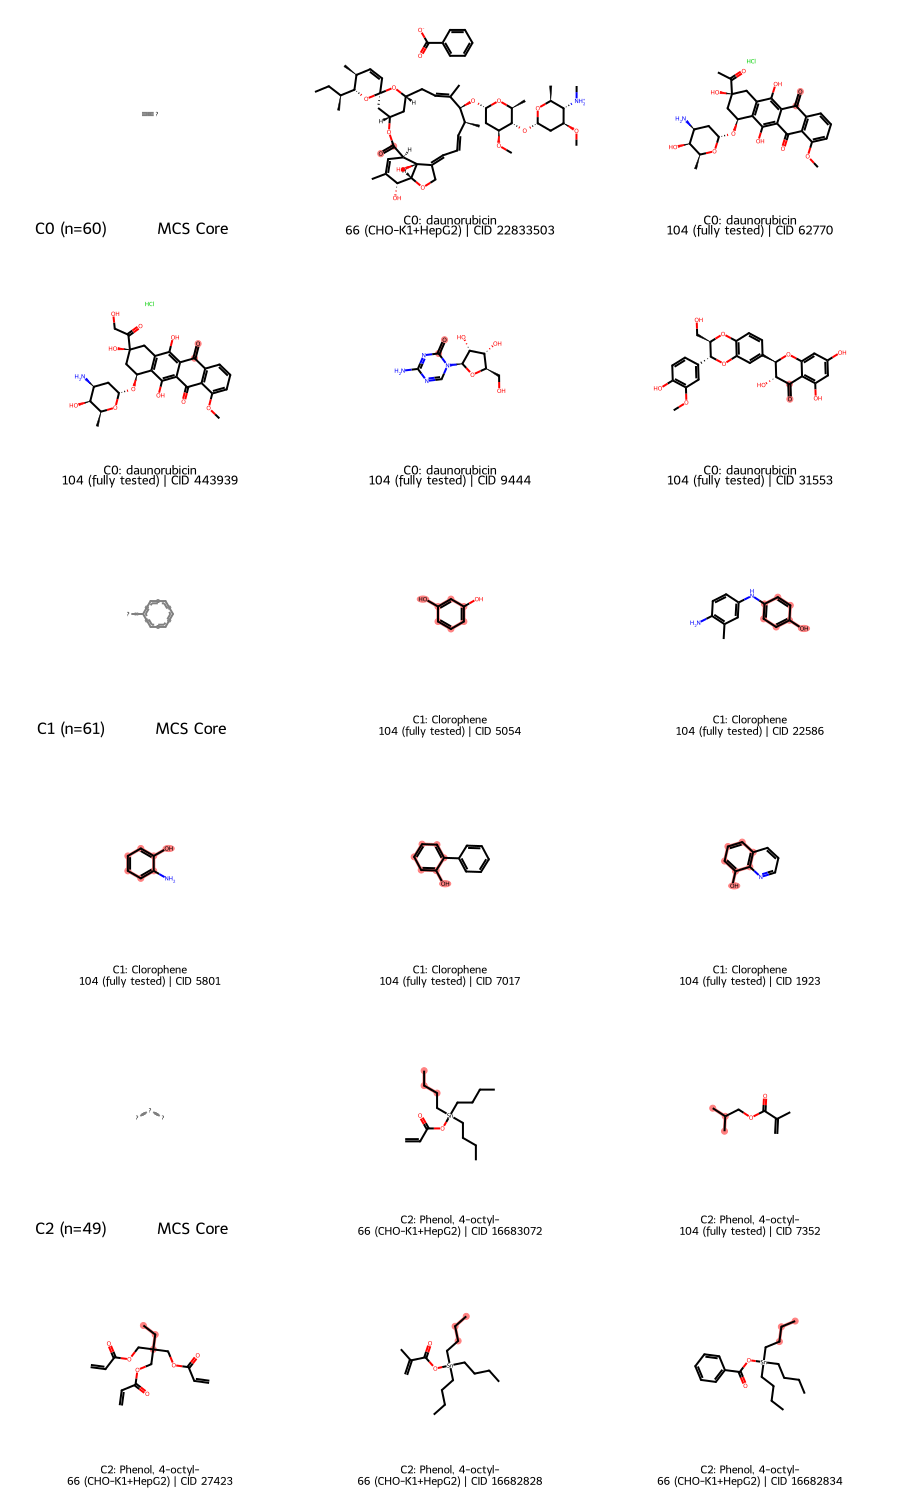

In [23]:
from IPython.display import display

CLUSTERS_170 = None
MOLS_PER_ROW = 3

cluster_ids_170 = sorted(g170['cluster'].unique())
if CLUSTERS_170 is not None:
    cluster_ids_170 = [c for c in cluster_ids_170 if c in CLUSTERS_170]

mols170, legs170, hi170 = [], [], []

for cl in cluster_ids_170:
    sub   = g170[g170['cluster'] == cl].reset_index(drop=True)
    shown = pick_central(sub)
    core  = get_mcs_core(shown['mol'].tolist())
    name  = cl_name_170.get(cl, f'Cluster {cl}')

    if core is not None:
        mols170.append(core)
        legs170.append(f'C{cl} (n={len(sub)}) ★ MCS Core ★')
        hi170.append([])

    for _, row in shown.iterrows():
        mol = row['mol']
        mols170.append(mol)
        legs170.append(f'C{cl}: {name}\n{row["group"]} | CID {int(row["PUBCHEM_CID"])}')
        match = mol.GetSubstructMatch(core) if core is not None else []
        hi170.append(list(match))

print(f'Drawing {len(mols170)} panels across {len(cluster_ids_170)} cluster(s)')
if mols170:
    img = Draw.MolsToGridImage(mols170, molsPerRow=MOLS_PER_ROW, subImgSize=(300, 250),
                               legends=legs170, highlightAtomLists=hi170, returnPNG=False)
    display(img)